# Task 4: Nonparamentric Model — the k-Nearest Neighbors Regressor

### Imports

In [23]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
import time

### Auxiliary functions

In [24]:
# got this code from https://stackoverflow.com/questions/17315737/split-a-large-pandas-dataframe
def fixed_size_subframes(data):
    n = 257
    return [data[i : i + n].copy() for i in range(0, data.shape[0], n)]


def remove_useless_rows(subframes):
    cleaned_subframes = []
    
    for df in subframes:
        mask = (df.drop(columns=['Id']) != 0).any(axis=1)
        cleaned_df = df[mask]
        if not cleaned_df.empty:
            cleaned_subframes.append(cleaned_df)
    
    return cleaned_subframes


def augment_dataset(df, features_to_drop=[], enable_euclidian_dist=False, enable_angles=False, enable_polars=False):
    # Calculate Euclidean distances between points
    if enable_euclidian_dist:
        df['dist_12'] = np.sqrt((df['x_2'] - df['x_1'])**2 + (df['y_2'] - df['y_1'])**2)
        df['dist_23'] = np.sqrt((df['x_3'] - df['x_2'])**2 + (df['y_3'] - df['y_2'])**2)
        df['dist_13'] = np.sqrt((df['x_3'] - df['x_1'])**2 + (df['y_3'] - df['y_1'])**2)

    # Calculate the angles between the points
    if enable_angles:
        df['angle_1'] = calculate_angle(df['x_1'], df['y_1'], df['x_2'], df['y_2'], df['x_3'], df['y_3'])
        df['angle_2'] = calculate_angle(df['x_2'], df['y_2'], df['x_1'], df['y_1'], df['x_3'], df['y_3'])
        df['angle_3'] = calculate_angle(df['x_3'], df['y_3'], df['x_1'], df['y_1'], df['x_2'], df['y_2'])

    # Calculate polar coordinates for each point
    if enable_polars:
        df['r_1'], df['theta_1'] = calculate_polar_coordinates(df['x_1'], df['y_1'])
        df['r_2'], df['theta_2'] = calculate_polar_coordinates(df['x_2'], df['y_2'])
        df['r_3'], df['theta_3'] = calculate_polar_coordinates(df['x_3'], df['y_3'])

    return df.drop(columns=features_to_drop)


def create_features_and_targets(subframes, features_to_drop=[], enable_euclidian_dist=False, enable_angles=False, enable_polars=False):
    feature_labels = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
    target_labels = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
    X_chunks = []
    y_chunks = []
    
    for df in subframes:        
        first_row = df.iloc[0][feature_labels].values
        
        X_chunk = np.column_stack((df['t'].values, np.tile(first_row, (len(df), 1))))
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        X_chunk_df = augment_dataset(X_chunk_df, features_to_drop, enable_euclidian_dist, enable_angles, enable_polars)
        
        y_chunk_df = df[target_labels].copy()
        y_chunk_df = augment_dataset(y_chunk_df, [], enable_euclidian_dist, enable_angles, enable_polars)
        
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks


def plot_y_yhat(y_test, y_pred, plot_title = "plot"):
    labels = ['x_1','y_1','x_2','y_2','x_3','y_3']
    MAX = 500
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test),MAX, replace=False)
    else:
        idx = np.arange(len(y_test))
    plt.figure(figsize=(10,10))
    for i in range(6):
        x0 = np.min(y_test[idx,i])
        x1 = np.max(y_test[idx,i])
        plt.subplot(3,2,i+1)
        plt.scatter(y_test[idx,i],y_pred[idx,i])
        plt.xlabel('True '+labels[i])
        plt.ylabel('Predicted '+labels[i])
        plt.plot([x0,x1],[x0,x1],color='red')
        plt.axis('square')
    plt.savefig(plot_title+'.pdf')
    plt.show()


def validate_knn_regression(X_train, y_train, X_val, y_val, X_test, y_test, ks=range(1,15), scaler=StandardScaler()):
    best_rmse = np.inf
    best_model = None
    best_k = None

    for k in ks:        
        knn_reg=make_pipeline(scaler, KNeighborsRegressor(n_neighbors=k))
        
        start_training_time = time.time()
        knn_reg.fit(X_train, y_train)
        end_training_time = time.time()
        execution_training_time = end_training_time - start_training_time

        start_inference_time = time.time()
        y_pred = knn_reg.predict(X_val)
        end_inference_time = time.time()
        execution_inference_time = end_inference_time - start_inference_time
        
        print(f"Training time: {execution_training_time} s | Inference time: {execution_inference_time} s")
        
        position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
        y_val_positions = y_val[position_columns].values
        y_pred_positions = y_pred[:, range(6)] 
        
        rmse = root_mean_squared_error(y_val_positions, y_pred_positions)
        
        print(f"K is {k} | RMSE: {rmse}")
        
        if rmse < best_rmse:
            best_rmse = rmse
            best_model = knn_reg
            best_k = k
            
    print(f"Best K: {best_k}, RMSE: {best_rmse}")
    
    return best_model, best_k, best_rmse


def save_predictions(predictions, path, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']):
    df = pd.DataFrame(predictions, columns=columns)
    df_positions = df[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    df_positions['Id'] = df_positions.index
    df_positions = df_positions[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    df_positions.to_csv(path, index=False)
        
# Written with GPT-4o     
def calculate_angle(x1, y1, x2, y2, x3, y3):
    v1_x = x2 - x1
    v1_y = y2 - y1
    
    v2_x = x3 - x1
    v2_y = y3 - y1
    
    dot_product = v1_x * v2_x + v1_y * v2_y
    
    magnitude_v1 = np.sqrt(v1_x**2 + v1_y**2)
    magnitude_v2 = np.sqrt(v2_x**2 + v2_y**2)
    
    cos_theta = dot_product / (magnitude_v1 * magnitude_v2 + 1e-10)
    
    return np.arccos(np.clip(cos_theta, -1, 1))

# Written with GPT-4o
def calculate_polar_coordinates(x, y):
    r = np.sqrt(x**2 + y**2)
    theta = np.arctan2(y, x)
    return r, theta

#### Load the dataset without velocities

In [13]:
df = pd.read_csv('../mlNOVA/X_train.csv')
df.drop(columns=['v_x_1','v_y_1','v_x_2','v_y_2','v_x_3','v_y_3'], inplace=True) # Velocities don't seem to help
df.head()

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
0,0.000000,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,0
1,0.039062,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1
2,0.078125,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,2
3,0.117188,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,3
4,0.156250,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,4


In [14]:
subframes = fixed_size_subframes(df)
subframes = remove_useless_rows(subframes)

### Only t and positions as features

Extract the features and targets

In [27]:
X_chunks, y_chunks = create_features_and_targets(subframes)

In [28]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

Trying out standard scaler first

Low values for K

In [29]:
std_model, std_k, std_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test)

Training time: 2.533956527709961 s | Inference time: 0.6529102325439453 s
K is 1 | RMSE: 1.1133085444555992
Training time: 2.5507848262786865 s | Inference time: 0.6891272068023682 s
K is 2 | RMSE: 1.1364861608551795
Training time: 2.557114601135254 s | Inference time: 0.7084145545959473 s
K is 3 | RMSE: 1.126873231940144
Training time: 2.5648081302642822 s | Inference time: 0.7683343887329102 s
K is 4 | RMSE: 1.1189392074479247
Training time: 2.5946857929229736 s | Inference time: 0.802070140838623 s
K is 5 | RMSE: 1.1259277120888218
Training time: 2.7030930519104004 s | Inference time: 0.8366260528564453 s
K is 6 | RMSE: 1.104610846694298
Training time: 2.5170674324035645 s | Inference time: 0.8831057548522949 s
K is 7 | RMSE: 1.0900808468954022
Training time: 2.7305243015289307 s | Inference time: 0.9224271774291992 s
K is 8 | RMSE: 1.0731520679543634
Training time: 2.5786116123199463 s | Inference time: 0.9731156826019287 s
K is 9 | RMSE: 1.0785877004950368
Training time: 2.5910360

Broader range of values for K

In [30]:
std_model, std_k, std_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, [20, 30, 40, 50, 71, 73, 75, 77, 79, 81, 83, 85, 100], StandardScaler())

Training time: 2.6299123764038086 s | Inference time: 1.3754143714904785 s
K is 20 | RMSE: 1.0197010333753955
Training time: 2.5696685314178467 s | Inference time: 1.643406629562378 s
K is 30 | RMSE: 1.003872146582568
Training time: 2.5921945571899414 s | Inference time: 1.99186372756958 s
K is 40 | RMSE: 1.0075467545682593
Training time: 2.610940456390381 s | Inference time: 2.22591233253479 s
K is 50 | RMSE: 0.9999885622266619
Training time: 2.677077531814575 s | Inference time: 2.928856372833252 s
K is 71 | RMSE: 1.0045419062018413
Training time: 2.6721689701080322 s | Inference time: 2.938934564590454 s
K is 73 | RMSE: 1.0037895307052649
Training time: 2.613412857055664 s | Inference time: 3.0986106395721436 s
K is 75 | RMSE: 1.0039843273678675
Training time: 2.6997830867767334 s | Inference time: 3.152317523956299 s
K is 77 | RMSE: 1.0050833228957516
Training time: 2.842684745788574 s | Inference time: 3.2168188095092773 s
K is 79 | RMSE: 1.005123090797719
Training time: 2.7277624

Best K is around the value 50

In [31]:
std_model, std_k, std_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, [45, 47, 49, 51, 53, 55, 57, 59, 61, 63, 65], StandardScaler())

Training time: 2.6232798099517822 s | Inference time: 2.122246026992798 s
K is 45 | RMSE: 1.0013447237075646
Training time: 2.5522289276123047 s | Inference time: 2.143158197402954 s
K is 47 | RMSE: 0.9999974396076275
Training time: 2.5886847972869873 s | Inference time: 2.2167317867279053 s
K is 49 | RMSE: 0.9984648869580574
Training time: 2.591585397720337 s | Inference time: 2.2861499786376953 s
K is 51 | RMSE: 1.002422361812732
Training time: 2.532015562057495 s | Inference time: 2.324000120162964 s
K is 53 | RMSE: 1.0036131017933736
Training time: 2.564652681350708 s | Inference time: 2.358051061630249 s
K is 55 | RMSE: 1.0031802036519977
Training time: 2.517702579498291 s | Inference time: 2.5338146686553955 s
K is 57 | RMSE: 1.0024808128254734
Training time: 2.5224661827087402 s | Inference time: 2.5463666915893555 s
K is 59 | RMSE: 1.0035807546833109
Training time: 2.542717218399048 s | Inference time: 2.563951015472412 s
K is 61 | RMSE: 1.00316244212159
Training time: 2.576210

##### Plot the test RMSE for the best model (K=49)
This is our final model

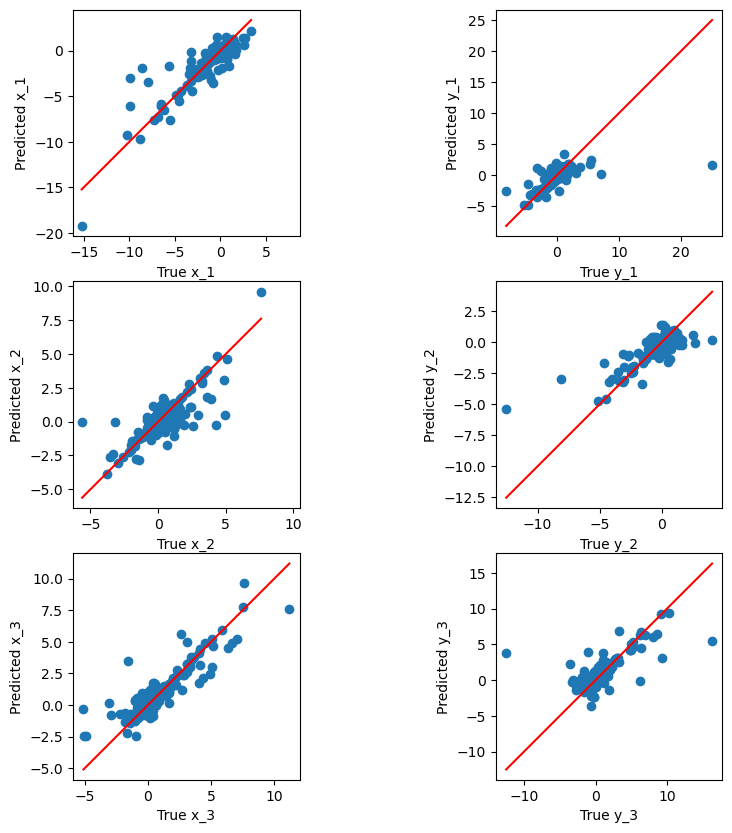

Test RMSE: 0.9784600414158925


In [35]:
y_test_pred = std_model.predict(X_test)

position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
y_test_pred_positions = y_test_pred[:, range(6)]
y_test_positions = y_test[position_columns].values

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")
rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

Generate a submission

In [32]:
X_kaggle_df_knn = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df_knn.drop(columns=['Id'], inplace=True)

X_kaggle_df_knn = augment_dataset(X_kaggle_df_knn)

In [33]:
y_knn_std_pred = std_model.predict(X_kaggle_df_knn)

In [34]:
save_predictions(y_knn_std_pred, '../submissions/knn_submission.csv')

Trying out MinMaxScaler

In [9]:
minmax_model, minmax_k, minmax_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, scaler=MinMaxScaler())

K is 1 | RMSE: 1.1829397430506097
K is 2 | RMSE: 1.1759011733639242
K is 3 | RMSE: 1.1765326125083182
K is 4 | RMSE: 1.150149091945914
K is 5 | RMSE: 1.1360935731226574
K is 6 | RMSE: 1.1007589849585695
K is 7 | RMSE: 1.0873033052939076
K is 8 | RMSE: 1.0753647603259602
K is 9 | RMSE: 1.0827437839130842
K is 10 | RMSE: 1.085400406447308
K is 11 | RMSE: 1.0663816340058354
K is 12 | RMSE: 1.0497941682368273
K is 13 | RMSE: 1.033798533092294
K is 14 | RMSE: 1.032775469284304
Best K: 14, RMSE: 1.032775469284304


## All positions and added features

Load data and extract features and targets

In [15]:
X_chunks, y_chunks = create_features_and_targets(subframes, enable_euclidian_dist=True, enable_angles=True, enable_polars=True)

X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

#### Standard scaler

##### Low values for K

In [25]:
std_model, std_k, std_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, [1, 3, 5, 7], StandardScaler())

Training time: 0.5578234195709229 s | Inference time: 105.45140409469604 s
K is 1 | RMSE: 1.1494698641148968
Training time: 0.4372553825378418 s | Inference time: 99.8064079284668 s
K is 3 | RMSE: 1.1479008542508096
Training time: 0.4544031620025635 s | Inference time: 99.05744218826294 s
K is 5 | RMSE: 1.1455721202368307
Training time: 0.4404928684234619 s | Inference time: 100.81502890586853 s
K is 7 | RMSE: 1.1421708771150878
Best K: 7, RMSE: 1.1421708771150878


Skip the next 3 blocks

In [ ]:
# X_kaggle_df_knn = pd.read_csv('../mlNOVA/X_test.csv')
# X_kaggle_df_knn.drop(columns=['Id'], inplace=True)

# X_kaggle_df_knn = augment_dataset(X_kaggle_df_knn, enable_euclidian_dist=True, enable_angles=True, enable_polars=True)

In [43]:
# y_knn_std_pred = std_model.predict(X_kaggle_df_knn)

In [44]:
# targets = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3', 'dist_12', 'dist_23', 'dist_13', 'angle_1', 'angle_2', 'angle_3', 'r_1', 'theta_1', 'r_2', 'theta_2', 'r_3', 'theta_3']
# save_predictions(y_knn_std_pred, '../submissions/knn_submission.csv', targets)

##### High values for K

In [26]:
std_model_alt, std_k_alt, std_rmse_alt = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, [50, 71, 73, 75, 77, 79, 81, 83, 85, 100], StandardScaler())

Training time: 0.46831297874450684 s | Inference time: 99.92012977600098 s
K is 50 | RMSE: 1.002309258868529
Training time: 0.46363377571105957 s | Inference time: 100.48084473609924 s
K is 71 | RMSE: 0.9964032356146605
Training time: 0.4809987545013428 s | Inference time: 106.78869819641113 s
K is 73 | RMSE: 0.9966157814284603
Training time: 0.4880971908569336 s | Inference time: 102.83696818351746 s
K is 75 | RMSE: 0.995349099094676
Training time: 0.44408559799194336 s | Inference time: 104.76137971878052 s
K is 77 | RMSE: 0.9952333520599913
Training time: 0.4634134769439697 s | Inference time: 99.32058191299438 s
K is 79 | RMSE: 0.9957564342769679
Training time: 0.49167728424072266 s | Inference time: 101.95446944236755 s
K is 81 | RMSE: 0.9952593106733473
Training time: 0.48212337493896484 s | Inference time: 99.34440612792969 s
K is 83 | RMSE: 0.9962173095130696
Training time: 0.4800429344177246 s | Inference time: 97.09388971328735 s
K is 85 | RMSE: 0.9956734462034685
Training ti

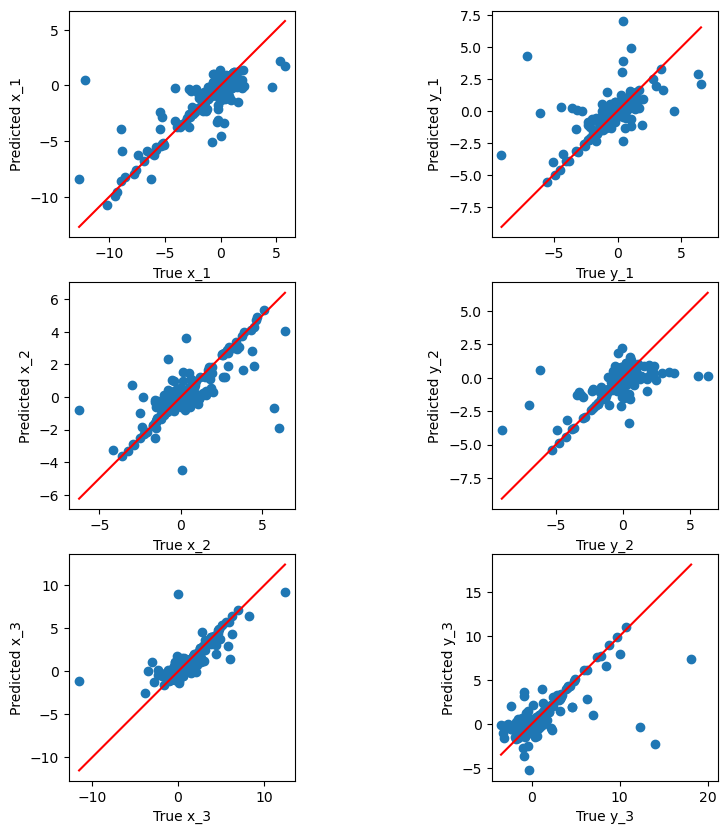

Test RMSE: 0.9753016803875235


In [40]:
y_test_pred_alt = std_model_alt.predict(X_test)

position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
y_test_pred_positions = y_test_pred_alt[:, range(6)]
y_test_positions = y_test[position_columns].values

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")
rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

Skip the next 3 blocks

In [15]:
# X_kaggle_df_knn = pd.read_csv('../mlNOVA/X_test.csv')
# X_kaggle_df_knn.drop(columns=['Id'], inplace=True)

# X_kaggle_df_knn = augment_dataset(X_kaggle_df_knn, enable_euclidian_dist=True, enable_angles=True, enable_polars=True)

In [18]:
# y_knn_std_pred_alt = std_model_alt.predict(X_kaggle_df_knn)

In [19]:
# targets = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3', 'dist_12', 'dist_23', 'dist_13', 'angle_1', 'angle_2', 'angle_3', 'r_1', 'theta_1', 'r_2', 'theta_2', 'r_3', 'theta_3']
# save_predictions(y_knn_std_pred_alt, '../submissions/knn_submission.csv', targets)

C:\Users\rasvi\AppData\Local\Temp\ipykernel_28664\2381563791.py:139: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_positions['Id'] = df_positions.index


#### MinMax scaler

We tried this scaler as well but the results weren't very interesting.

In [18]:
minmax_model, minmax_k, minmax_rmse = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, [1, 3, 5, 7], MinMaxScaler())

K is 1 | RMSE: 1.1501327796778267
K is 3 | RMSE: 1.1495448740278946
K is 5 | RMSE: 1.1469978529966902
K is 7 | RMSE: 1.1441355639787927
Best K: 7, RMSE: 1.1441355639787927


In [19]:
minmax_model_alt, minmax_k_alt, minmax_rmse_alt = validate_knn_regression(X_train, y_train, X_dev, y_dev, X_test, y_test, [10, 20, 30, 40, 50, 75, 100], MinMaxScaler())

K is 10 | RMSE: 1.1190432106999122
K is 20 | RMSE: 1.0555452112361527
K is 30 | RMSE: 1.0168234834757297
K is 40 | RMSE: 1.0021113351101256
K is 50 | RMSE: 1.0021580857791945
K is 75 | RMSE: 0.999397484517671
K is 100 | RMSE: 0.9983831409707351
Best K: 100, RMSE: 0.9983831409707351
